In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('loan_approval_dataset.csv')

In [3]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
df.shape

(4269, 13)

In [5]:
df.columns = df.columns.str.strip()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [7]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [8]:
print(df.isnull().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [10]:
df["education"].value_counts()

education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

In [11]:
df["self_employed"].value_counts()

self_employed
Yes    2150
No     2119
Name: count, dtype: int64

In [12]:
df["loan_status"].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [13]:
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

In [14]:
df.drop("loan_id", axis=1, inplace=True)

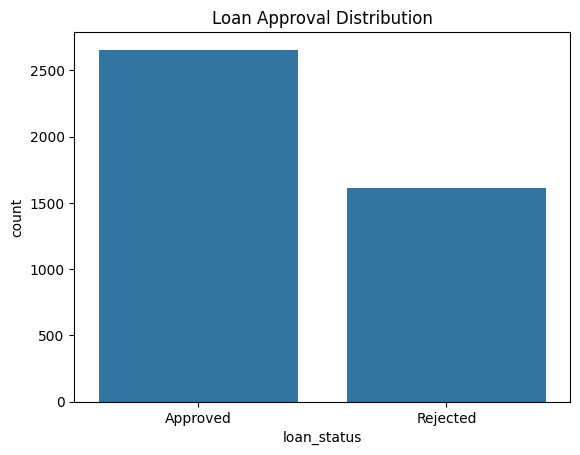

In [15]:
sns.countplot(
    x="loan_status",
    data=df
)

plt.title("Loan Approval Distribution")
plt.show()

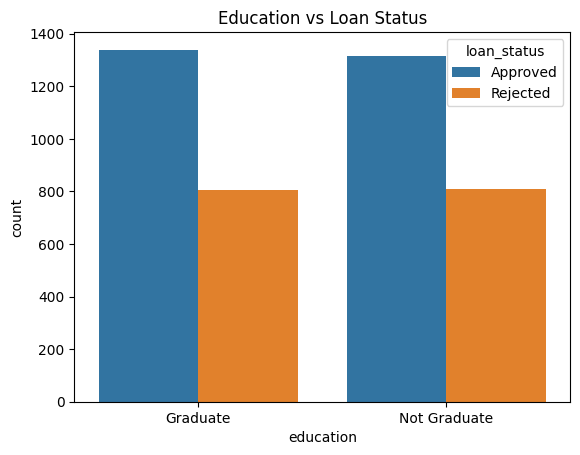

In [16]:
sns.countplot(
    x="education",
    hue="loan_status",
    data=df
)

plt.title("Education vs Loan Status")
plt.show()

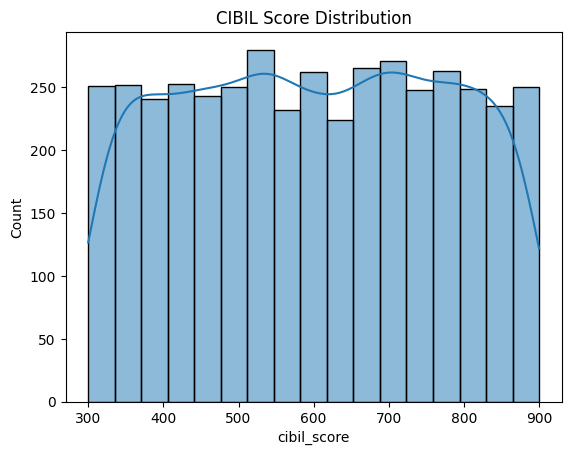

In [17]:
sns.histplot(
    df["cibil_score"],
    kde=True
)

plt.title("CIBIL Score Distribution")
plt.show()

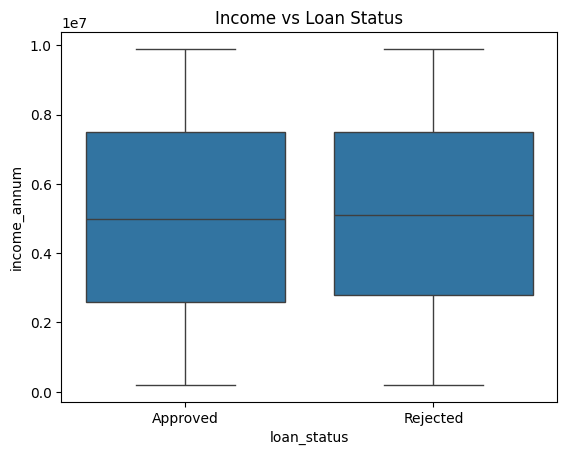

In [18]:
sns.boxplot(
    x="loan_status",
    y="income_annum",
    data=df
)

plt.title("Income vs Loan Status")
plt.show()

In [19]:
df["education"] = df["education"].map({
    "Graduate": 1,
    "Not Graduate": 0
})

In [20]:
df["self_employed"] = df["self_employed"].map({
    "Yes": 1,
    "No": 0
})

In [21]:
df["loan_status"] = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

In [22]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


In [23]:
X = df.drop("loan_status", axis=1)

y = df["loan_status"]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
)

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [27]:
scaler.fit_transform(X_train)

array([[ 0.89071783,  0.99853694, -1.00852831, ..., -1.13730558,
        -0.44443983, -0.73682658],
       [ 0.30110717,  0.99853694,  0.99154381, ...,  0.78599456,
        -0.04838711, -0.39679525],
       [-0.28850349,  0.99853694,  0.99154381, ...,  1.74764462,
         1.30479299,  0.71603457],
       ...,
       [ 0.30110717,  0.99853694,  0.99154381, ...,  0.32806595,
        -0.3894325 , -0.42770719],
       [-1.46772481,  0.99853694, -1.00852831, ..., -0.83965199,
        -0.6974735 ,  0.37600323],
       [ 0.30110717,  0.99853694, -1.00852831, ...,  1.47288746,
         1.43681056,  2.10707184]], shape=(3415, 11))

In [28]:
scaler.transform(X_test)

array([[ 0.30110717, -1.0014652 ,  0.99154381, ..., -0.7709627 ,
         0.22664949,  0.3450913 ],
       [ 0.89071783, -1.0014652 ,  0.99154381, ..., -0.26724123,
        -0.47744422, -0.58226688],
       [-0.87811415,  0.99853694, -1.00852831, ..., -0.79385913,
         0.76572124,  0.31417936],
       ...,
       [ 0.89071783,  0.99853694,  0.99154381, ..., -1.11440915,
        -0.60946179,  0.59238681],
       [ 1.48032849,  0.99853694, -1.00852831, ..., -1.02282343,
        -1.5885921 , -1.41688925],
       [ 0.30110717,  0.99853694,  0.99154381, ...,  0.12199808,
         1.65683984,  0.59238681]], shape=(854, 11))

In [29]:
lr_model = LogisticRegression(
    max_iter=1000
)

lr_model.fit(
    X_train_scaled,
    y_train
)

lr_prediction = lr_model.predict(
    X_test_scaled
)

In [30]:
lr_accuracy = accuracy_score(
    y_test,
    lr_prediction
)

print(
    "Logistic Regression Accuracy:",
    lr_accuracy
)

Logistic Regression Accuracy: 0.9133489461358314


In [31]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

dt_prediction = dt_model.predict(
    X_test
)

dt_accuracy = accuracy_score(
    y_test,
    dt_prediction
)

print(
    "Decision Tree Accuracy:",
    dt_accuracy
)

Decision Tree Accuracy: 0.9812646370023419


In [32]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

rf_prediction = rf_model.predict(
    X_test
)

rf_accuracy = accuracy_score(
    y_test,
    rf_prediction
)

print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.9836065573770492


In [33]:
results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ]

})

print(results)

                 Model  Accuracy
0  Logistic Regression  0.913349
1        Decision Tree  0.981265
2        Random Forest  0.983607


In [34]:
print(
    classification_report(
        y_test,
        rf_prediction
    )
)

              precision    recall  f1-score   support

           0       0.98      0.97      0.98       323
           1       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



In [35]:
import joblib
joblib.dump(rf_model, "loan_model.pkl")

['loan_model.pkl']

## Phase 1: 5-Model Comparison (LR, DT, RF, SVM, Gaussian NB)
Compare 5 classifiers matching syllabus experiments.
- Scale features with `StandardScaler` inside a `Pipeline` for Logistic Regression and SVM only.
- Decision Tree, Random Forest, and Gaussian Naive Bayes do not require feature scaling.
- Evaluated on test set with 5 metrics: Accuracy, Precision, Recall, F1, and ROC-AUC.
- Save comparison table to `results/model_comparison.csv` and ROC curve points to `results/roc.json`.


In [36]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
import json
import os

# Models to compare:
# - Logistic Regression & SVM use StandardScaler inside Pipeline
# - Decision Tree, Random Forest, and Gaussian NB use unscaled features
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=42))
    ]),
    "Gaussian Naive Bayes": GaussianNB()
}

results_list = []
roc_curves = {}

os.makedirs("results", exist_ok=True)

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    
    results_list.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })
    
    roc_curves[name] = {
        "fpr": fpr.tolist(),
        "tpr": tpr.tolist(),
        "auc": round(auc, 4)
    }

comparison_df = pd.DataFrame(results_list)
print("=== 5-Model Comparison Results ===")
print(comparison_df.to_string(index=False))

# Save results
comparison_df.to_csv("results/model_comparison.csv", index=False)
with open("results/roc.json", "w") as f:
    json.dump(roc_curves, f, indent=2)

print("\nSaved results to results/model_comparison.csv and results/roc.json")


=== 5-Model Comparison Results ===
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
   Logistic Regression    0.9133     0.9208  0.9416    0.9311   0.9726
         Decision Tree    0.9813     0.9849  0.9849    0.9849   0.9801
         Random Forest    0.9836     0.9832  0.9906    0.9869   0.9989
Support Vector Machine    0.9450     0.9583  0.9529    0.9556   0.9865
  Gaussian Naive Bayes    0.7529     0.7216  0.9812    0.8316   0.9604

Saved results to results/model_comparison.csv and results/roc.json
